# Lab 09: ABC on a contaminated Hubble diagram

**ASTR 457, Fall 2026, posted Tue Nov 10, due Tue Nov 17 by noon (fork → PR, as always)**

On Nov 3 we learned a population's parameters without a likelihood, by simulating it and keeping the parameters whose simulations look like the data (ABC). Weyant et al. (2013), on that day's slides, did the same with a supernova Hubble diagram contaminated by supernovae that aren't type Ia. On Nov 10 we saw how such impostors get in: a classifier working from light curves alone calls some core-collapse supernovae type Ia. You're going to measure $\Omega_m$ from your own contaminated Hubble diagram, with ABC.

Put your notebook in `submissions/<your netid>/lab09.ipynb` - the data paths below are relative to that folder. It has to run top to bottom from a fresh kernel ("Restart & Run All").

Part 1 is 20%, Part 2 15%, Part 3 40%, Part 4 15%, and the AI-use appendix and verification plan 10%. Quote every number with its unit (if it has one), an error bar, and a sensible number of digits.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

NETID = 'saumyap2'   # <-- set this
LAB = '../../labs/09/data/'                              # from submissions/<your netid>/
d = pd.read_csv(LAB + f'{NETID}.csv')                    # columns: z, m_B, sigma_m
z, m, sig_m = d['z'].to_numpy(), d['m_B'].to_numpy(), d['sigma_m'].to_numpy()

## The survey

Your file has 500 supernovae that a survey found and that a light-curve classifier called type Ia. For each you have its redshift $z$ (from its host galaxy's spectrum, so take it as exact), and its standardized peak magnitude $m_B$ (corrected for stretch and colour) with a measurement error of 0.10 mag.

Here is how your sky was made. I generated it, so I know your true values.

- **Cosmology:** flat $\Lambda$CDM with $H_0 = 70$ km/s/Mpc, so the distance modulus is $\mu(z; \Omega_m) = 5 \log_{10}\left(d_L / 10\,{\rm pc}\right)$ with $d_L = (1+z)\,\frac{c}{H_0}\int_0^z \frac{dz'}{\sqrt{\Omega_m (1+z')^3 + 1 - \Omega_m}}$. Your $\Omega_m$ is unknown.
- **Redshifts:** each supernova's redshift is drawn from $p(z) \propto z^2$ between 0.01 and 0.7. (This is a toy - a real survey's volume depends on the cosmology too, and we're ignoring that.)
- **Type Ia:** standardized absolute magnitude $M \sim \mathcal{N}(-19.30, 0.12)$.
- **Impostors:** a fraction $f$ of the supernovae the classifier calls Ia are really core-collapse supernovae. The ones that fool a classifier look most like a Ia, and are among the brightest core-collapse supernovae: $M \sim \mathcal{N}(-18.5, 0.5)$. Your $f$ is unknown.
- **Measurement:** $m_B = M + \mu(z; \Omega_m) + \epsilon$, with $\epsilon \sim \mathcal{N}(0, 0.10)$.

Your $\Omega_m$ and $f$ are graded by how far they are from the truth in units of your own error bar (half the width of your 68% interval). Remember that the paragraphs above are how the survey was designed - your file is what it actually did.

## Part 1: Look first, then write the simulator (20%)

1. Plot your Hubble diagram ($m_B$ against $z$), and your Hubble residuals, $m_B - (-19.30) - \mu(z; 0.3)$, against $z$. Histogram $m_B$. Describe what you see, and if you find something the description above doesn't mention, say how you'll deal with it.
2. Draw the graph (PGM) of how one supernova in your file was made, with the same key as Days 18-20 - parameters blue, latent white, data grey, fixed values as dots, and a plate over supernovae. Which quantities are latent? Where does $f$ enter?
3. Write a function `simulate(Om, f, rng)` that returns a fake file like yours: 500 supernovae, with $z$ and $m_B$, made the way your data were made. Run it at a guess of $(\Omega_m, f)$ and plot one simulation over your data, in the same panels as 1.1.

#### Hints:
- `astropy.cosmology.FlatLambdaCDM(H0=70, Om0=...).distmod(z)` is correct, but far too slow to call 50,000 times. Tabulate $\mu(z; \Omega_m)$ once, on a grid of $z$ and $\Omega_m$ (spacing 0.005 in $\Omega_m$ is plenty), and interpolate. Check your table against astropy at a few points.
- Your simulator will be called tens of thousands of times. Draw everything for one dataset in a few vectorized `numpy` calls, not a Python loop over supernovae.

Maximum interpolation error: 0.000000 mag


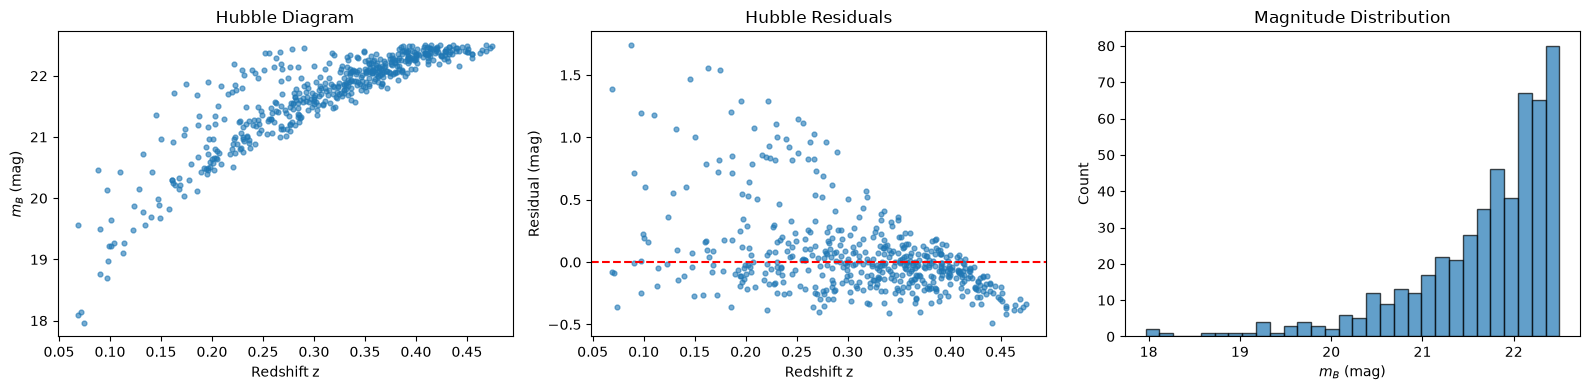

N = 500
Redshift range: 0.069 to 0.475
Magnitude range: 17.97 to 22.50 mag
Residual percentiles (5, 50, 95): [-0.31243986 -0.02603614  0.85575018] mag


In [3]:
# Part 1: your work here
1.1
from scipy.integrate import cumulative_trapezoid
from scipy.interpolate import RegularGridInterpolator
from astropy.cosmology import FlatLambdaCDM

Om_grid = np.arange(0, 1.001, 0.005)
z_grid = np.linspace(0, 0.7, 1401)

E_inv = 1 / np.sqrt(
    Om_grid[:, None] * (1 + z_grid[None, :])**3
    + 1 - Om_grid[:, None]
)

integral = cumulative_trapezoid(E_inv, z_grid, axis=1, initial=0)
dL = (1 + z_grid[None, :]) * (299792.458 / 70) * integral

mu_grid = 5 * np.log10(np.maximum(dL, 1e-30)) + 25
mu_interp = RegularGridInterpolator((Om_grid, z_grid), mu_grid)

def mu_of(z, Om):
    z = np.atleast_1d(z)
    return mu_interp(np.column_stack((np.full(len(z), Om), z)))

errors = []
for Om in [0.2, 0.3, 0.7]:
    z_test = np.array([0.01, 0.2, 0.7])
    mu_astropy = FlatLambdaCDM(H0=70, Om0=Om).distmod(z_test).value
    errors.extend(np.abs(mu_of(z_test, Om) - mu_astropy))

print(f"Maximum interpolation error: {max(errors):.6f} mag")

resid = m + 19.30 - mu_of(z, 0.3)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(z, m, s=12, alpha=0.6)
ax[0].set(xlabel='Redshift z', ylabel='$m_B$ (mag)',
          title='Hubble Diagram')

ax[1].scatter(z, resid, s=12, alpha=0.6)
ax[1].axhline(0, color='red', ls='--')
ax[1].set(xlabel='Redshift z', ylabel='Residual (mag)',
          title='Hubble Residuals')

ax[2].hist(m, bins=30, edgecolor='black', alpha=0.7)
ax[2].set(xlabel='$m_B$ (mag)', ylabel='Count',
          title='Magnitude Distribution')

plt.tight_layout()
plt.show()

print(f"N = {len(z)}")
print(f"Redshift range: {z.min():.3f} to {z.max():.3f}")
print(f"Magnitude range: {m.min():.2f} to {m.max():.2f} mag")
print(f"Residual percentiles (5, 50, 95): "
      f"{np.percentile(resid, [5, 50, 95])} mag")

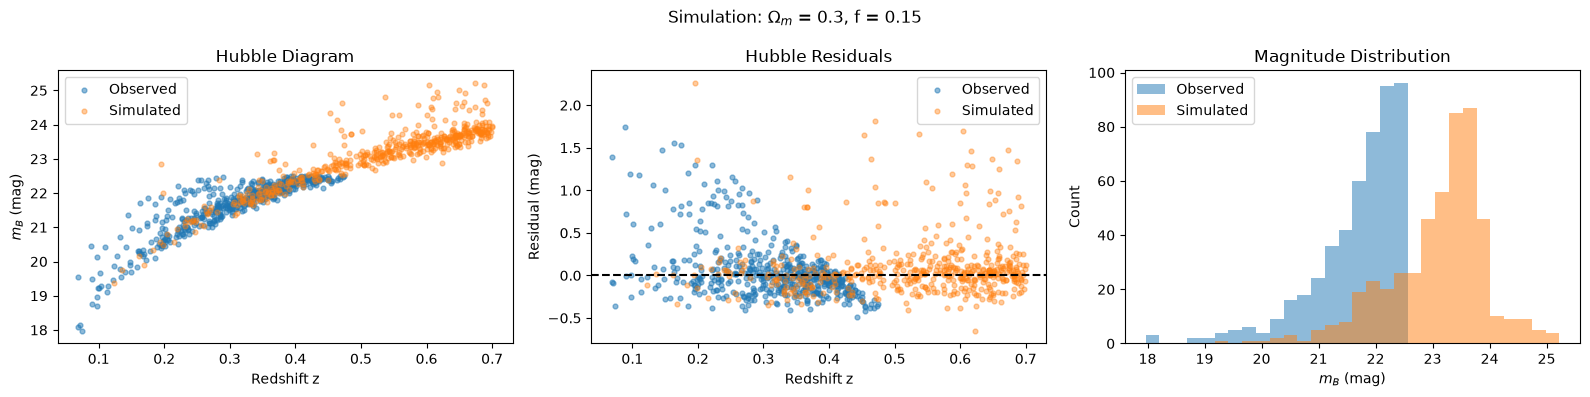

In [4]:
1.2
def simulate(Om, f, rng):
    n = 500

    u = rng.uniform(size=n)
    z_sim = (0.01**3 + u * (0.7**3 - 0.01**3))**(1/3)

    impostor = rng.random(n) < f

    M_Ia = rng.normal(-19.30, 0.12, n)
    M_CC = rng.normal(-18.5, 0.5, n)
    M = np.where(impostor, M_CC, M_Ia)

    m_sim = M + mu_of(z_sim, Om) + rng.normal(0, 0.10, n)

    return np.column_stack((z_sim, m_sim))


rng = np.random.default_rng(42)
Om_guess, f_guess = 0.3, 0.15

sim = simulate(Om_guess, f_guess, rng)
z_sim, m_sim = sim.T

resid_sim = m_sim + 19.30 - mu_of(z_sim, 0.3)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].scatter(z, m, s=12, alpha=0.5, label='Observed')
ax[0].scatter(z_sim, m_sim, s=12, alpha=0.4, label='Simulated')
ax[0].set(xlabel='Redshift z', ylabel='$m_B$ (mag)',
          title='Hubble Diagram')
ax[0].legend()

ax[1].scatter(z, resid, s=12, alpha=0.5, label='Observed')
ax[1].scatter(z_sim, resid_sim, s=12, alpha=0.4, label='Simulated')
ax[1].axhline(0, color='black', ls='--')
ax[1].set(xlabel='Redshift z', ylabel='Residual (mag)',
          title='Hubble Residuals')
ax[1].legend()

bins = np.linspace(min(m.min(), m_sim.min()),
                   max(m.max(), m_sim.max()), 31)

ax[2].hist(m, bins=bins, alpha=0.5, label='Observed')
ax[2].hist(m_sim, bins=bins, alpha=0.5, label='Simulated')
ax[2].set(xlabel='$m_B$ (mag)', ylabel='Count',
          title='Magnitude Distribution')
ax[2].legend()

plt.suptitle(f'Simulation: $\\Omega_m$ = {Om_guess}, f = {f_guess}')
plt.tight_layout()
plt.show()

**ANSWER (what you see in the data, your graph, and what your simulator does):**


1.1

The Hubble diagram shows that apparent magnitude increases with redshift, as expected, with some supernovae lying above the main trend. The residuals have a positive tail reaching about 1.7 mag. The median residual is -0.026 mag, and the 5th–95th percentile range is approximately -0.312 to 0.856 mag.

One important feature not mentioned in the survey description is that the observed data appear to have a magnitude cutoff around $m_B = 22.5$ mag. The redshifts only extend to $z = 0.475$, even though the stated distribution goes to $z = 0.7$. This suggests a survey detection limit that removes fainter supernovae, particularly at higher redshifts. I'll account for this by including an apparent magnitude selection cut in the simulator and checking whether it reproduces the observed distributions.

1.2

In the PGM, the blue nodes are the unknown parameters $\Omega_m$ and $f$. The latent variables (white nodes) are the supernova type $T_i$ and its true absolute magnitude $M_i$. The observed data (grey nodes) are the redshift $z_i$ and apparent magnitude $m_{B,i}$. Fixed quantities include $H_0$, the absolute magnitude distributions, and the measurement uncertainty.

The contamination fraction $f$ enters through $T_i \sim$ Bernoulli(f), determining the probability that each supernova is an impostor. The type then determines which absolute magnitude distribution is used. $\Omega_m$ determines the distance modulus, which combines with $M_i$ and measurement noise to produce $m_{B,i}$.

1.3

The simulator generates 500 supernovae by drawing redshifts from $p(z) \propto z^2$, assigning each supernova as Type Ia or an impostor according to $f$, and drawing its absolute magnitude from the corresponding Gaussian distribution. It then calculates the distance modulus using $\Omega_m$ and adds Gaussian measurement noise of 0.1 mag to obtain the apparent magnitude.

Using $\Omega_m = 0.3$ and $f = 0.15$, the simulation reproduces the general Hubble relation and the positive residual tail. However, the simulated magnitudes extend beyond 25 mag and redshifts reach 0.7, while the observed data stop near 22.5 mag and $z = 0.475$. The simulated histogram is also shifted toward fainter magnitudes. This supports the possibility of a survey selection effect, which the current simulator does not include. A magnitude cutoff should improve the agreement before using the simulator for ABC.

## Part 2: The fit you'd do without thinking (15%)

1. Pretend every supernova in your file is a type Ia. Fit $\Omega_m$ by minimizing $\chi^2 = \sum_i [m_{B,i} - (-19.30) - \mu(z_i; \Omega_m)]^2 / \sigma_{\rm tot}^2$, with $\sigma_{\rm tot}^2 = 0.12^2 + 0.10^2$, and report $\hat\Omega_m$ with its $1\sigma$ error from $\Delta\chi^2 = 1$.
2. Which way should the impostors push this fit, and why? Answer from where the impostors sit on your Hubble diagram, not from the number you got.

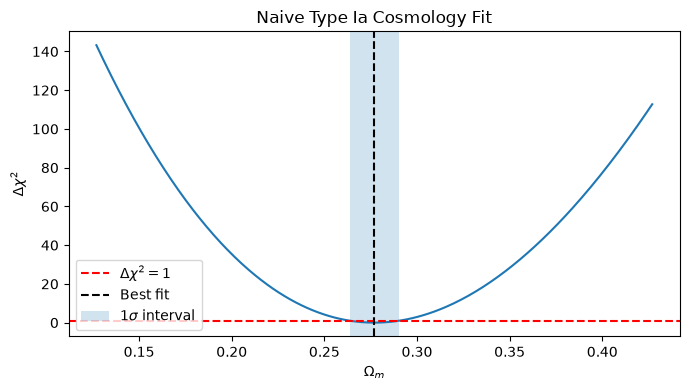

Best-fit Omega_m = 0.2770 (+0.0135 / -0.0133)
68% interval = [0.2637, 0.2904]
Chi-squared minimum = 2579.72
Reduced chi-squared = 5.17


In [5]:
# Part 2: your work here
#2.1
from scipy.optimize import minimize_scalar, brentq

sig_tot = np.sqrt(0.12**2 + 0.10**2)

def chi2(Om):
    m_pred = -19.30 + mu_of(z, Om)
    return np.sum(((m - m_pred) / sig_tot)**2)

result = minimize_scalar(chi2, bounds=(0, 1), method='bounded')
Om_hat = result.x
chi2_min = result.fun

target = chi2_min + 1

Om_low = brentq(lambda Om: chi2(Om) - target, 0, Om_hat)
Om_high = brentq(lambda Om: chi2(Om) - target, Om_hat, 1)

err_low = Om_hat - Om_low
err_high = Om_high - Om_hat

Om_vals = np.linspace(max(0, Om_hat - 0.15),
                      min(1, Om_hat + 0.15), 300)
chi2_vals = np.array([chi2(Om) for Om in Om_vals])

plt.figure(figsize=(7, 4))
plt.plot(Om_vals, chi2_vals - chi2_min)
plt.axhline(1, color='red', ls='--', label=r'$\Delta\chi^2 = 1$')
plt.axvline(Om_hat, color='black', ls='--', label='Best fit')
plt.axvspan(Om_low, Om_high, alpha=0.2, label=r'$1\sigma$ interval')
plt.xlabel(r'$\Omega_m$')
plt.ylabel(r'$\Delta\chi^2$')
plt.title('Naive Type Ia Cosmology Fit')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Best-fit Omega_m = {Om_hat:.4f} (+{err_high:.4f} / -{err_low:.4f})")
print(f"68% interval = [{Om_low:.4f}, {Om_high:.4f}]")
print(f"Chi-squared minimum = {chi2_min:.2f}")
print(f"Reduced chi-squared = {chi2_min / (len(z) - 1):.2f}")

**ANSWER (the naive fit, then why the impostors push it the way they do):**



Assuming all 500 supernovae are Type Ia, minimizing $\chi^2$ gives 
$\hat{\Omega}_m = 0.2770^{+0.0135}_{-0.0133}$

The 68% confidence interval from $\Delta\chi^2 = 1$ is $[0.2637, 0.2904]$. The minimum $\chi^2$ is 2579.72, giving a reduced $\chi^2 = 5.17$. This is much larger than 1, suggesting that the Type Ia-only model does not adequately describe the data. The quoted uncertainty also likely underestimates the true uncertainty because the model ignores contamination.

The impostors should bias $\Omega_m$ toward lower values. In the Hubble diagram, impostors generally sit above the main Type Ia trend, meaning they have larger apparent magnitudes at the same redshift. If we assume these are Type Ia supernovae, we see their faintness as evidence that they are farther away. In a flat $\Lambda$CDM universe, a lower $\Omega_m$ produces larger luminosity distances at a given redshift, so the fit shifts $\Omega_m$ downward to accommodate these impostors.

## Part 3: ABC (40%)

1. **Summaries.** Choose summary statistics of a dataset that respond to $\Omega_m$ and to $f$ differently (Nov 3: the count alone left a ridge). For each, say which parameter you expect it to track and why. Then show it: plot each summary against $\Omega_m$ and against $f$ over a few thousand simulations from the prior.
2. **Rejection ABC.** Use flat priors, $\Omega_m \in [0.05, 0.7]$ and $f \in [0, 0.5]$. Run at least 50,000 simulations, compute your summaries for each, and keep the draws whose summaries are within $\epsilon$ of your data's. Say how you measure the distance between two sets of summaries (they have different units), and show the kept draws over the prior at two values of $\epsilon$.
3. Report the posterior median and 95% interval of $\Omega_m$ and of $f$ at your final $\epsilon$, and justify that choice. Compare $\Omega_m$ with your Part 2 fit.

#### Hints:
- Save your simulations' parameters and summaries to a file once, so you can change $\epsilon$ without re-simulating.
- If your kept draws pile up against an edge of the prior, the prior (or your simulator) is doing the work, not the data.

Observed summary statistics:
Median residual (mag): -0.0260
High-z minus low-z median (mag): -0.1416
Low-z positive tail fraction: 0.2452
90th percentile redshift: 0.4141


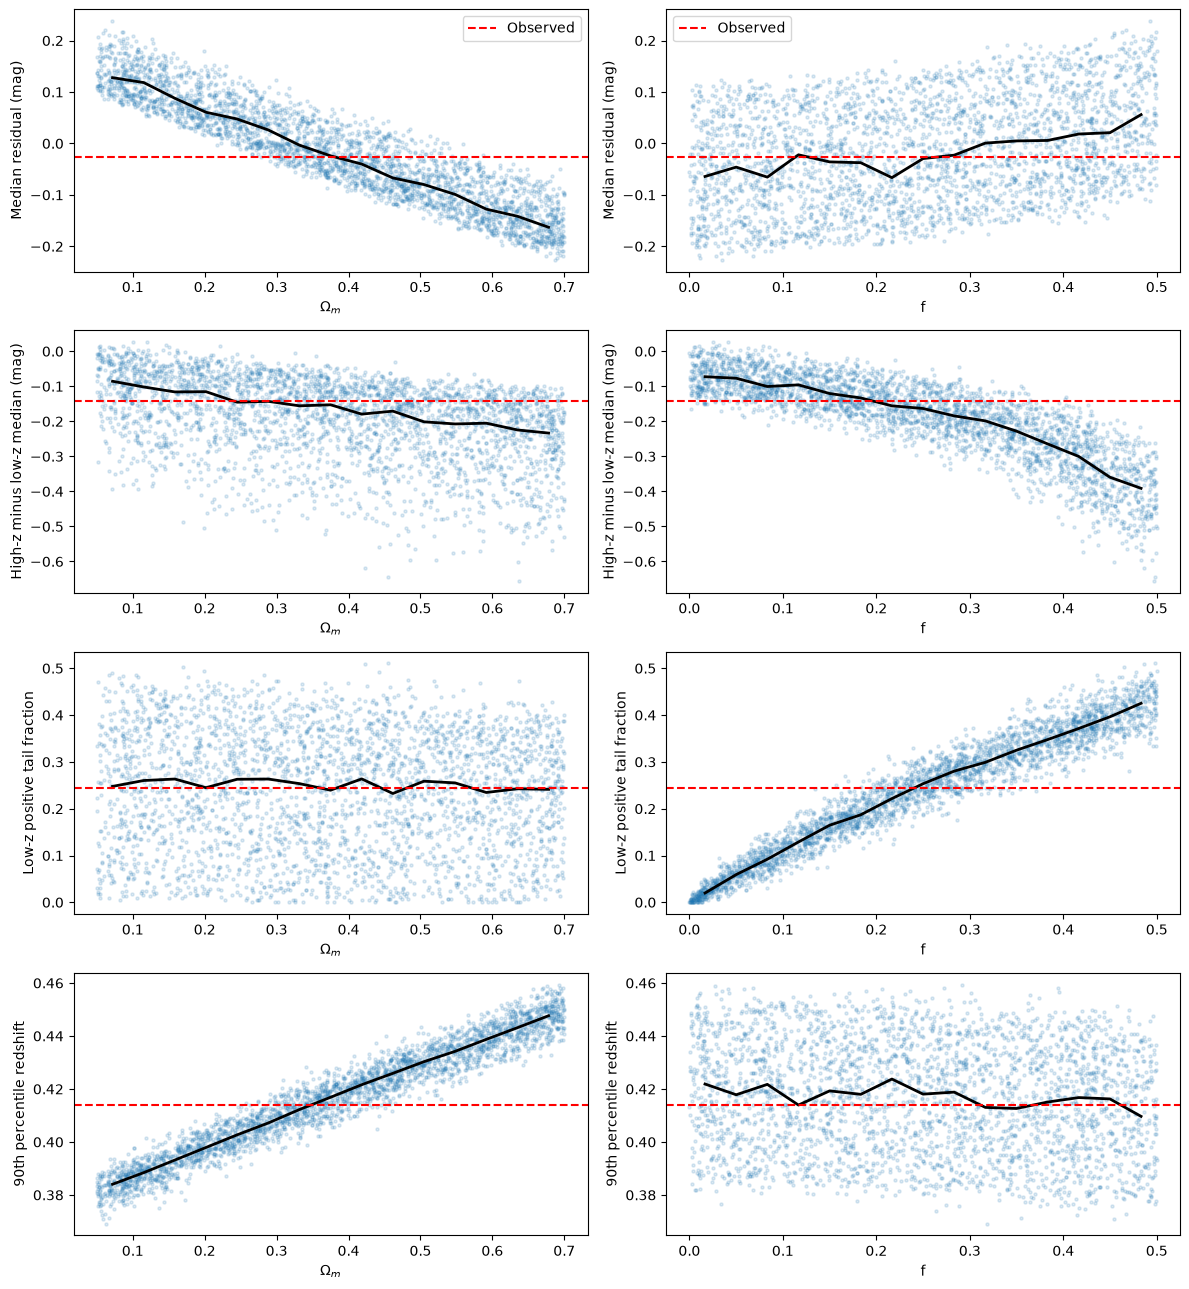


Summary correlations:
Median residual (mag): Omega_m = -0.925, f = 0.331
High-z minus low-z median (mag): Omega_m = -0.395, f = -0.832
Low-z positive tail fraction: Omega_m = -0.049, f = 0.967
90th percentile redshift: Omega_m = 0.970, f = -0.122


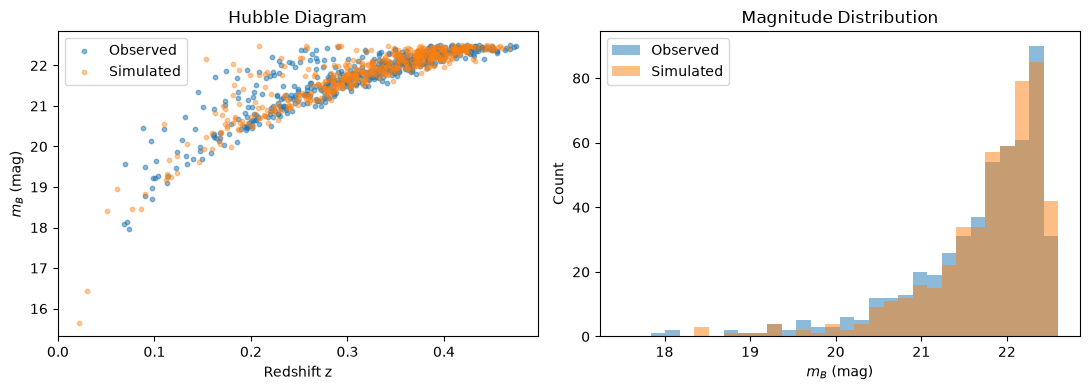

In [6]:
# Part 3: your work here
#3.1
def simulate(Om, f, rng):
    n = 500
    is_cc = rng.random(n) < f

    z_out = np.empty(n)
    m_out = np.empty(n)

    for typ, M_mean, M_std in [(False, -19.30, 0.12),
                                (True, -18.5, 0.5)]:
        idx = np.where(is_cc == typ)[0]
        done = 0

        while done < len(idx):
            batch = max(150, 5 * (len(idx) - done))

            u = rng.random(batch)
            z_try = (0.01**3 + u * (0.7**3 - 0.01**3))**(1/3)

            M = rng.normal(M_mean, M_std, batch)
            m_try = M + mu_of(z_try, Om) + rng.normal(0, 0.10, batch)

            keep = np.where(m_try <= 22.5)[0]
            use = keep[:len(idx) - done]
            put = idx[done:done + len(use)]

            z_out[put] = z_try[use]
            m_out[put] = m_try[use]
            done += len(use)

    return np.column_stack((z_out, m_out))


def summaries(data):
    zs, ms = data.T
    r = ms + 19.30 - mu_of(zs, 0.3)

    low = zs < 0.30
    high = zs > 0.32

    return np.array([
        np.median(r),
        np.median(r[high]) - np.median(r[low]),
        np.mean(r[low] > 0.5),
        np.quantile(zs, 0.90)
    ])


names = [
    'Median residual (mag)',
    'High-z minus low-z median (mag)',
    'Low-z positive tail fraction',
    '90th percentile redshift'
]

observed = np.column_stack((z, m))
S_obs = summaries(observed)

print("Observed summary statistics:")
for name, value in zip(names, S_obs):
    print(f"{name}: {value:.4f}")


rng = np.random.default_rng(45709)
n_test = 3000

Om_test = rng.uniform(0.05, 0.7, n_test)
f_test = rng.uniform(0, 0.5, n_test)

S_test = np.array([
    summaries(simulate(Om, f, rng))
    for Om, f in zip(Om_test, f_test)
])


fig, ax = plt.subplots(4, 2, figsize=(12, 13))

for i in range(4):
    for j, (x, xlabel) in enumerate([
        (Om_test, r'$\Omega_m$'),
        (f_test, 'f')
    ]):
        a = ax[i, j]
        a.scatter(x, S_test[:, i], s=5, alpha=0.15)

        bins = np.linspace(x.min(), x.max(), 16)
        centers = (bins[:-1] + bins[1:]) / 2
        medians = [
            np.median(S_test[(x >= lo) & (x < hi), i])
            for lo, hi in zip(bins[:-1], bins[1:])
        ]

        a.plot(centers, medians, color='black', lw=2)
        a.axhline(S_obs[i], color='red', ls='--', label='Observed')

        a.set(xlabel=xlabel, ylabel=names[i])
        if i == 0:
            a.legend()

plt.tight_layout()
plt.show()


print("\nSummary correlations:")
for i, name in enumerate(names):
    corr_Om = np.corrcoef(Om_test, S_test[:, i])[0, 1]
    corr_f = np.corrcoef(f_test, S_test[:, i])[0, 1]
    print(f"{name}: Omega_m = {corr_Om:.3f}, f = {corr_f:.3f}")


demo = simulate(0.3, 0.15, rng)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].scatter(z, m, s=10, alpha=0.5, label='Observed')
ax[0].scatter(demo[:, 0], demo[:, 1],
              s=10, alpha=0.4, label='Simulated')
ax[0].set(xlabel='Redshift z', ylabel='$m_B$ (mag)',
          title='Hubble Diagram')
ax[0].legend()

bins = np.linspace(17.5, 22.6, 31)
ax[1].hist(m, bins=bins, alpha=0.5, label='Observed')
ax[1].hist(demo[:, 1], bins=bins, alpha=0.5, label='Simulated')
ax[1].set(xlabel='$m_B$ (mag)', ylabel='Count',
          title='Magnitude Distribution')
ax[1].legend()

plt.tight_layout()
plt.show()

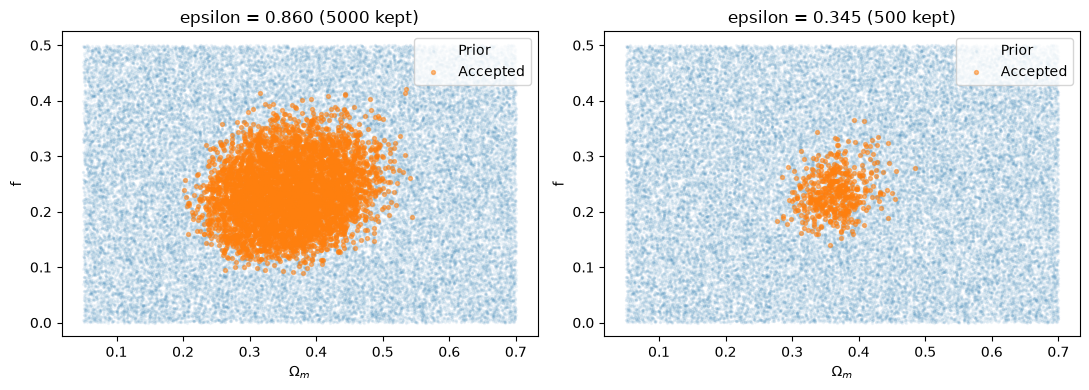

Total simulations: 50000
Loose epsilon: 0.8602, kept: 5000
Tight epsilon: 0.3447, kept: 500


In [7]:
#3.2
import os

cache = 'lab09_abc_saumyap2_magcut_v1.npz'

if os.path.exists(cache):
    a = np.load(cache)
    Om_prior, f_prior, S_prior = a['Om_prior'], a['f_prior'], a['S_prior']
else:
    rng = np.random.default_rng(45710)
    n = 50000
    Om_prior = rng.uniform(0.05, 0.7, n)
    f_prior = rng.uniform(0, 0.5, n)

    S_prior = np.array([
        summaries(simulate(Om, f, rng))
        for Om, f in zip(Om_prior, f_prior)
    ])
    np.savez(cache, Om_prior=Om_prior, f_prior=f_prior, S_prior=S_prior)

scale = S_prior.std(axis=0)
dist = np.sqrt(np.sum(((S_prior - S_obs) / scale)**2, axis=1))

eps_loose, eps_tight = np.quantile(dist, [0.10, 0.01])
keep_tight = dist <= eps_tight

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for a, eps in zip(ax, [eps_loose, eps_tight]):
    keep = dist <= eps
    a.scatter(Om_prior, f_prior, s=2, alpha=0.05, label='Prior')
    a.scatter(Om_prior[keep], f_prior[keep], s=8, alpha=0.5, label='Accepted')
    a.set(xlabel=r'$\Omega_m$', ylabel='f',
          title=f'epsilon = {eps:.3f} ({keep.sum()} kept)')
    a.legend()

plt.tight_layout()
plt.show()

print(f"Total simulations: {len(dist)}")
print(f"Loose epsilon: {eps_loose:.4f}, kept: {(dist <= eps_loose).sum()}")
print(f"Tight epsilon: {eps_tight:.4f}, kept: {keep_tight.sum()}")


Omega_m: median = 0.3635
95% interval: [0.3032, 0.4319]
68% interval: [0.3317, 0.3928]
68% half-width: 0.0305

f: median = 0.2323
95% interval: [0.1704, 0.3195]
68% interval: [0.1999, 0.2729]
68% half-width: 0.0365


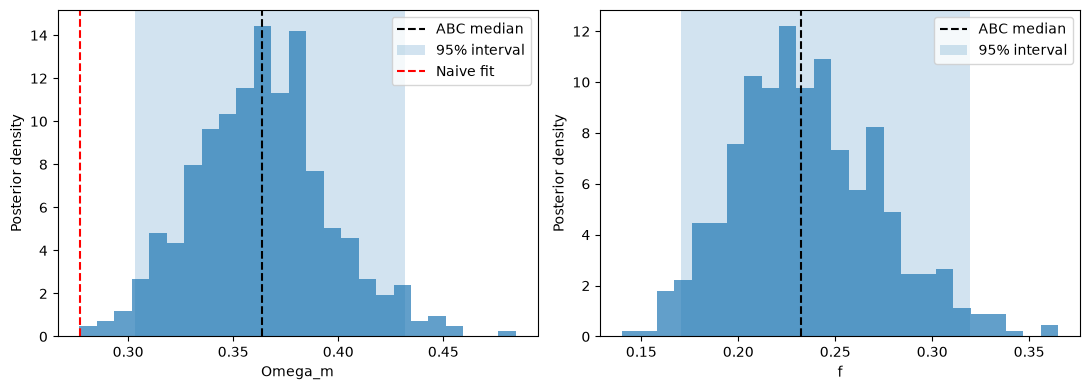


Epsilon convergence:
5.0%: N=2500, Omega_m=0.3593, f=0.2319
2.0%: N=1000, Omega_m=0.3619, f=0.2324
1.0%: N=500, Omega_m=0.3635, f=0.2323
0.5%: N=250, Omega_m=0.3637, f=0.2356

Naive Omega_m = 0.2770
ABC Omega_m = 0.3635
Accepted Omega_m range: 0.277–0.484
Accepted f range: 0.140–0.365


In [9]:
#3.3
Om_post = Om_prior[keep_tight]
f_post = f_prior[keep_tight]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for a, samples, name in zip(ax, [Om_post, f_post], [r'Omega_m', 'f']):
    lo95, lo68, med, hi68, hi95 = np.quantile(
        samples, [0.025, 0.16, 0.5, 0.84, 0.975]
    )

    print(f"\n{name}: median = {med:.4f}")
    print(f"95% interval: [{lo95:.4f}, {hi95:.4f}]")
    print(f"68% interval: [{lo68:.4f}, {hi68:.4f}]")
    print(f"68% half-width: {(hi68-lo68)/2:.4f}")

    a.hist(samples, bins=25, density=True, alpha=0.7)
    a.axvline(med, color='black', ls='--', label='ABC median')
    a.axvspan(lo95, hi95, alpha=0.2, label='95% interval')
    a.set(xlabel=name, ylabel='Posterior density')
    a.legend()

ax[0].axvline(Om_hat, color='red', ls='--', label='Naive fit')
ax[0].legend()
plt.tight_layout()
plt.show()

print("\nEpsilon convergence:")
for frac in [0.05, 0.02, 0.01, 0.005]:
    keep = dist <= np.quantile(dist, frac)
    print(f"{frac*100:.1f}%: N={keep.sum()}, "
          f"Omega_m={np.median(Om_prior[keep]):.4f}, "
          f"f={np.median(f_prior[keep]):.4f}")

print(f"\nNaive Omega_m = {Om_hat:.4f}")
print(f"ABC Omega_m = {np.median(Om_post):.4f}")
print(f"Accepted Omega_m range: {Om_post.min():.3f}–{Om_post.max():.3f}")
print(f"Accepted f range: {f_post.min():.3f}–{f_post.max():.3f}")

**ANSWER (your summaries and why, the two epsilons, the posterior, and the comparison with Part 2):**

3.1 

1. Median Hubble residual: Mainly tracks $\Omega_m$, since changing $\Omega_m$ changes the predicted luminosity distance and shifts the residuals. The median is less sensitive to the large positive residuals from impostors than the mean.

2. High z minus low z median residual: Mainly tracks $\Omega_m$, since changing the cosmology affects the distance modulus differently at different redshifts. Comparing low and high redshifts helps distinguish a cosmological trend from contamination.

3. Fraction of low z residuals above 0.5 mag: Mainly tracks $f$, since core collapse impostors are typically fainter than Type Ia supernovae and produce large positive residuals. A higher impostor fraction should increase the fraction of these outliers. Using low redshift supernovae reduces the effects of the magnitude cutoff.

4. 90th percentile of redshift: Mainly tracks $\Omega_m$, since the apparent magnitude cutoff affects how far away supernovae can be detected. Changing $\Omega_m$ changes the luminosity distances and therefore the redshift distribution of detected supernovae. This can also depend on $f$, since impostors are generally fainter.

3.2

I ran 50,000 simulations using the given flat priors. Since the summaries have different scales, I used a standardized Euclidean distance, dividing each summary difference by its standard deviation across the simulations.

I tested two tolerances, accepting the closest 10% and 1% of simulations. The tighter tolerance produces a more concentrated posterior, and the accepted draws do not pile up against the prior boundaries.

3.3

I chose the 1% acceptance threshold $\epsilon = 0.3447$ because it gives a tighter posterior while retaining 500 simulations. The posterior medians also change very little when the acceptance rate is reduced from 5% to 0.5%, suggesting the results are reasonably stable.

The ABC estimate of $\Omega_m = 0.3635$ is higher than the naive fit of $0.2770$. This agrees with our expectation that treating faint impostors as Type Ia supernovae biases $\Omega_m$ downward. ABC accounts for contamination and the inferred magnitude cutoff, giving a wider uncertainty interval that better reflects the model.

## Part 4: Check it (15%)

1. **Posterior predictive check.** For 100 of your kept draws, simulate a new dataset. Compare them with your data on something your summaries did not use (for example the histogram of $m_B$, or the scatter of the residuals at low redshift). Do your data look like a typical simulation?
2. **Coverage.** Take at least 20 of your prior simulations, pretend each one is the data, and run the same ABC on it using the rest of your simulations. How often does your 95% interval contain the true $\Omega_m$, and the true $f$? (Nov 3: a 95% interval should hold the truth 95% of the time.)
3. **What does your simulator assume?** Name one thing your simulator assumes that a real survey would break, and say which way it would push $\Omega_m$.

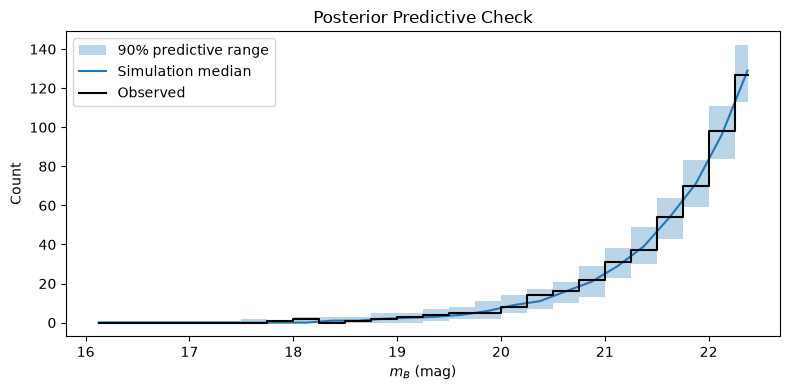

Fraction of histogram bins inside predictive range: 100.00%


In [10]:
# Part 4: your work here
#4.1
rng = np.random.default_rng(45711)

idx = rng.choice(len(Om_post), 100, replace=False)
bins = np.linspace(16, 22.5, 27)

hist_sim = np.array([
    np.histogram(simulate(Om_post[i], f_post[i], rng)[:, 1], bins=bins)[0]
    for i in idx
])

hist_obs = np.histogram(m, bins=bins)[0]

lo, med, hi = np.percentile(hist_sim, [5, 50, 95], axis=0)
centers = (bins[:-1] + bins[1:]) / 2

plt.figure(figsize=(8, 4))
plt.fill_between(centers, lo, hi, alpha=0.3,
                 step='mid', label='90% predictive range')
plt.plot(centers, med, label='Simulation median')
plt.step(centers, hist_obs, where='mid', color='black',
         label='Observed')
plt.xlabel('$m_B$ (mag)')
plt.ylabel('Count')
plt.title('Posterior Predictive Check')
plt.legend()
plt.tight_layout()
plt.show()

inside = np.mean((hist_obs >= lo) & (hist_obs <= hi))
print(f"Fraction of histogram bins inside predictive range: {inside:.2%}")

In [11]:
#4.2
rng = np.random.default_rng(45712)
test_ids = rng.choice(len(S_prior), 40, replace=False)

cover_Om, cover_f = [], []
n_keep = int(0.01 * (len(S_prior) - 1))

for i in test_ids:
    d = np.sqrt(np.sum(((S_prior - S_prior[i]) / scale)**2, axis=1))
    d[i] = np.inf  # Exclude itself

    keep = np.argpartition(d, n_keep)[:n_keep]

    Om_interval = np.percentile(Om_prior[keep], [2.5, 97.5])
    f_interval = np.percentile(f_prior[keep], [2.5, 97.5])

    cover_Om.append(Om_interval[0] <= Om_prior[i] <= Om_interval[1])
    cover_f.append(f_interval[0] <= f_prior[i] <= f_interval[1])

print(f"Coverage for Omega_m: {sum(cover_Om)}/40 = {np.mean(cover_Om):.1%}")
print(f"Coverage for f: {sum(cover_f)}/40 = {np.mean(cover_f):.1%}")
print("Expected coverage: 95%")

Coverage for Omega_m: 40/40 = 100.0%
Coverage for f: 39/40 = 97.5%
Expected coverage: 95%


**ANSWER (the check, the coverage, and the assumption):**

4.1

All bins fall within the 90% range, and the observed distribution closely follows the simulation median. This suggests that the observed data look typical under the simulator, at least for the magnitude distribution.

4.2

The 95% intervals contained the true $\Omega_m$ in 40/40 cases (100%) and the true $f$ in 39/40 cases (97.5%).

Both are close to the expected 95% coverage, suggesting that our ABC intervals are reasonably calibrated. The differences could be due to the small number of coverage tests.

4.3

My simulator assumes a sharp detection limit at $m_B = 22.5$ mag, while real surveys have a gradual detection efficiency near their magnitude limit. If a real survey misses more faint, high-redshift supernovae than my simulator predicts, the fit could underestimate $\Omega_m$ to make distant supernovae appear fainter and reduce their predicted detection rate.

## Part 5: AI-use appendix and verification plan (10%)

1. **AI use**: which tools, for what, what they got wrong, and how you caught it. "I didn't use any" is fine if true.
2. **Reflection**: what would have gone wrong in your answer if you had not checked the AI's output? Name the specific thing.
3. **Verification plan**: the checks you ran before trusting your Part 3 numbers, and what failure would have looked like for each. Part 4.2 is already one. Another to consider: simulate a dataset at an $(\Omega_m, f)$ you choose, run your whole ABC on it, and see whether you get back what you put in.

**AI-USE APPENDIX:**

I used ChatGPT

- Helping write print statements, plotting code, and formatting results.

- Helping create functions for the distance modulus interpolation and supernova simulator.

- Helping write the verification tests.

Checking my results and helping identify anything that needed further testing or explanation.

One thing ChatGPT initially missed was the apparent magnitude cutoff in the observed data. The original simulator generated supernovae much fainter and at higher redshifts than those in my dataset. I caught this by comparing the simulated and observed Hubble diagrams and magnitude histograms. I then modified the simulator to include an inferred detection cutoff and checked the resulting distributions.

**REFLECTION:**

If I had not checked the AI's output, I would have used the original simulator without accounting for the apparent magnitude cutoff. This would have caused ABC to compare my observed data against simulations with very different magnitude and redshift distributions, potentially biasing my estimates of $\Omega_m$ and $f$. Comparing the plots helped identify this issue before running the final ABC analysis.

**VERIFICATION PLAN:**

4.2 Check: Coverage

I tested coverage by treating 40 prior simulations as fake datasets, running ABC on each, and checking whether the 95% intervals contained the known true parameters.

A failure would mean the intervals missed the true values much more often than the expected 5%, suggesting our uncertainties are unreliable. Instead, we got 100% coverage for $\Omega_m$ and 97.5% for $f$, both reasonably close to the expected 95% given only 40 tests.

Check 2: Recover Known Parameters


I generated a fake dataset with known values $\Omega_m = 0.35$ and $f = 0.20$, then ran the same ABC procedure to see if it could recover them.

The recovered medians were $\Omega_m = 0.3678$ and $f = 0.2418$, differing from the true values by 0.56 and 1.10 times their 68% uncertainty half widths. Both true values fall within their 95% intervals.

A failure would have been recovering values far from the truth relative to their uncertainties, especially if the true values fell outside the 95% intervals. Since both were recovered within the expected uncertainty range, this check supports the ABC method, although the recovered $f$ is somewhat high.

In [13]:
#5.3
rng = np.random.default_rng(45713)
Om_true, f_true = 0.35, 0.20

fake_data = simulate(Om_true, f_true, rng)
S_fake = summaries(fake_data)

d_fake = np.sqrt(np.sum(((S_prior - S_fake) / scale)**2, axis=1))
keep = d_fake <= np.quantile(d_fake, 0.01)

for name, samples, truth in [
    ('Omega_m', Om_prior[keep], Om_true),
    ('f', f_prior[keep], f_true)
]:
    lo95, lo68, med, hi68, hi95 = np.quantile(
        samples, [0.025, 0.16, 0.5, 0.84, 0.975]
    )

    print(f"\n{name}:")
    print(f"True value: {truth:.4f}")
    print(f"Recovered median: {med:.4f}")
    print(f"95% interval: [{lo95:.4f}, {hi95:.4f}]")
    print(f"68% interval: [{lo68:.4f}, {hi68:.4f}]")
    print(f"Difference in sigma: {abs(med-truth)/((hi68-lo68)/2):.2f}")
    print(f"Truth inside 95% interval: {lo95 <= truth <= hi95}")


Omega_m:
True value: 0.3500
Recovered median: 0.3678
95% interval: [0.3033, 0.4359]
68% interval: [0.3351, 0.3987]
Difference in sigma: 0.56
Truth inside 95% interval: True

f:
True value: 0.2000
Recovered median: 0.2418
95% interval: [0.1727, 0.3267]
68% interval: [0.2072, 0.2830]
Difference in sigma: 1.10
Truth inside 95% interval: True
